## 1. Imports and project paths

The path setup below searches the current directory and its parents for the project-level `src` folder. This lets the notebook be run from a `notebooks/` directory or the project root.

In [11]:
import sys
from functools import partial
from pathlib import Path

import torch
from torch import nn
from torch.utils.data import DataLoader, random_split

# Find the project root (the directory containing src/).
current_dir = Path.cwd()
project_root = next(
    (path for path in [current_dir, *current_dir.parents] if (path / "src").is_dir()),
    None
)

if project_root is None:
    raise FileNotFoundError("Could not find the project root containing the 'src' directory.")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

DATA_ROOT = project_root / "data" / "aclImdb"
if not DATA_ROOT.exists():
    raise FileNotFoundError(f"IMDb dataset directory not found: {DATA_ROOT}")

## 2. Load the IMDb dataset

The dataset returns raw review text and an integer label (`1` for positive, `0` for negative). We keep the official test set separate and split the official training set into training and validation subsets.

In [12]:
from src.data.dataset import IMDbDataset
from src.data.tokenizer import WhitespaceTokenizer
from src.data.vocabulary import Vocabulary
from src.models.linear import LinearModel, LinearWithReluModel

train_dataset = IMDbDataset(DATA_ROOT, train=True)
test_dataset = IMDbDataset(DATA_ROOT, train=False)

print(f"Training examples available: {len(train_dataset)}")
print(f"Test examples: {len(test_dataset)}")

# Reserve 10% of the original training data for validation.
train_size = int(0.9 * len(train_dataset))
val_size = len(train_dataset) - train_size

generator = torch.Generator().manual_seed(42)
train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size],
    generator=generator
)

print(f"Training subset: {len(train_subset)}")
print(f"Validation subset: {len(val_subset)}")

Training examples available: 25000
Test examples: 25000
Training subset: 22500
Validation subset: 2500


## 3. Build the vocabulary and DataLoaders

The vocabulary is built **only from the training subset**. This avoids using validation or test text when deciding which tokens belong to the vocabulary.

The vocabulary maps each token to an integer ID. Those IDs are useful for lookup, but they are not meaningful numerical features by themselves.

In [13]:
tokenizer = WhitespaceTokenizer()
vocab = Vocabulary(tokenizer, min_freq=2)
vocab.build([review for review, _ in train_subset])

print(f"Vocabulary size (including special tokens): {len(vocab)}")

Vocabulary size (including special tokens): 102801


In [14]:
from src.data.preprocessing import collate_fn

collate = partial(collate_fn, vocab=vocab)

train_loader = DataLoader(
    train_subset,
    batch_size=32,
    shuffle=True,
    collate_fn=collate
)

val_loader = DataLoader(
    val_subset,
    batch_size=32,
    shuffle=False,
    collate_fn=collate
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    collate_fn=collate
)

## 4. Define the model

The final layer returns raw logits; do not add Softmax when training with `CrossEntropyLoss`.

In [15]:
from src.models.rnn import RNN

model = RNN(
    vocab_size=len(vocab), 
    embedding_size=100, 
    hidden_size=128,
    output_size=2
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

## 5. Train and Evaluate the Classifier

In [16]:
from pathlib import Path
Path("saved_models").mkdir(parents=True, exist_ok=True)

num_epochs = 10
train_losses = []
val_losses = []
best_val_loss = float("inf")

for epoch in range(num_epochs):
    # Training
    model.train()
    train_loss = 0.0

    for inputs, labels in train_loader:
        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    # Validation
    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            val_loss += loss.item()

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    avg_train_loss = train_loss / len(train_loader)
    avg_val_loss = val_loss / len(val_loader)
    val_accuracy = correct / total

    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)

    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss

        torch.save(
            model.state_dict(),
            "saved_models/best_single_rnn_model.pth"
        )

        print("Best model saved!")

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

Best model saved!
Epoch 1/10 | Train Loss: 0.6893 | Val Loss: 0.6829 | Val Accuracy: 0.5496
Best model saved!
Epoch 2/10 | Train Loss: 0.6393 | Val Loss: 0.6225 | Val Accuracy: 0.6652
Best model saved!
Epoch 3/10 | Train Loss: 0.5868 | Val Loss: 0.6211 | Val Accuracy: 0.6768
Best model saved!
Epoch 4/10 | Train Loss: 0.5114 | Val Loss: 0.6166 | Val Accuracy: 0.6964
Epoch 5/10 | Train Loss: 0.4821 | Val Loss: 0.6249 | Val Accuracy: 0.6936
Epoch 6/10 | Train Loss: 0.4164 | Val Loss: 0.6841 | Val Accuracy: 0.6660
Epoch 7/10 | Train Loss: 0.4275 | Val Loss: 0.6576 | Val Accuracy: 0.6432
Epoch 8/10 | Train Loss: 0.4520 | Val Loss: 0.6865 | Val Accuracy: 0.6008
Epoch 9/10 | Train Loss: 0.5053 | Val Loss: 0.7042 | Val Accuracy: 0.6180
Epoch 10/10 | Train Loss: 0.4764 | Val Loss: 0.7436 | Val Accuracy: 0.6252


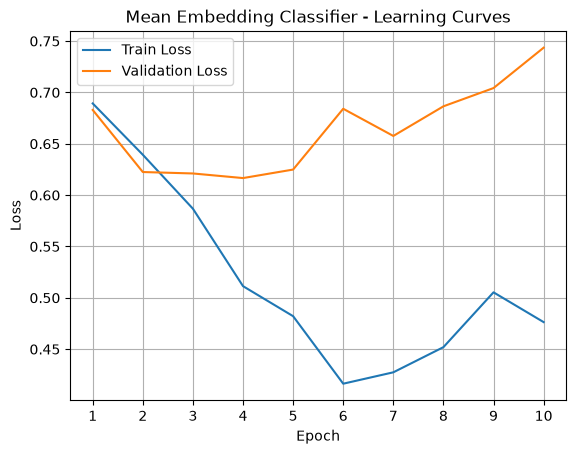

In [17]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.plot(epochs, train_losses, label="Train Loss")
plt.plot(epochs, val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Mean Embedding Classifier - Learning Curves")
plt.legend()
plt.xticks(epochs)
plt.grid(True)
plt.show()

## 6. Load the best model
We load the best model based on which obtained the lowest validation loss across the epochs

In [18]:
model.load_state_dict(
    torch.load("saved_models/best_single_rnn_model.pth", map_location="cpu")
)

<All keys matched successfully>

## 7. Test the model on the test set

In [19]:
test_loss = 0.0
correct = 0
total = 0

model.eval()

with torch.no_grad():
    for inputs, labels in test_loader:
        outputs = model(inputs)
        loss = criterion(outputs, labels)

        test_loss += loss.item()

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

avg_test_loss = test_loss / len(test_loader)
test_accuracy = correct / total

print(f"Test Loss: {avg_test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Test Loss: 0.5999
Test Accuracy: 0.7078


As we can see from the losses the RNN finds difficult learning this task. It is possible that the main cause is in the number of tokens taken from each sequence that makes too many steps for the gradient to propagate correctly (vanishing and exploding gradient problem).
Next we will try using just 128 tokens from a single review, discarding a lot of information.

In [20]:
collate = partial(collate_fn, vocab=vocab, max_length=128)

train_loader = DataLoader(
    train_subset,
    batch_size=32,
    shuffle=True,
    collate_fn=collate
)

val_loader = DataLoader(
    val_subset,
    batch_size=32,
    shuffle=False,
    collate_fn=collate
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    collate_fn=collate
)

In [ ]:
model = RNN(
    vocab_size=len(vocab), 
    embedding_size=100, 
    hidden_size=128,
    output_size=2
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

from pathlib import Path
Path("saved_models").mkdir(parents=True, exist_ok=True)

num_epochs = 10
train_losses = []
val_losses = []
best_val_loss = float("inf")

for epoch in range(num_epochs):
    # Training
    model.train()
    train_loss = 0.0

    for inputs, labels in train_loader:
        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        print("W gradient:", model.W.weight.grad.norm().item())     # inspect the gradient of W and U
        print("U gradient:", model.U.weight.grad.norm().item())
        optimizer.step()

        train_loss += loss.item()

    # Validation
    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            val_loss += loss.item()

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    avg_train_loss = train_loss / len(train_loader)
    avg_val_loss = val_loss / len(val_loader)
    val_accuracy = correct / total

    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)

    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss

        torch.save(
            model.state_dict(),
            "saved_models/best_single_rnn_model_shorter.pth"
        )

        print("Best model saved!")

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

Best model saved!
Epoch 1/10 | Train Loss: 0.6953 | Val Loss: 0.6910 | Val Accuracy: 0.5236
Best model saved!
Epoch 2/10 | Train Loss: 0.6784 | Val Loss: 0.6886 | Val Accuracy: 0.5440
Best model saved!
Epoch 3/10 | Train Loss: 0.6551 | Val Loss: 0.6830 | Val Accuracy: 0.5664
Epoch 4/10 | Train Loss: 0.6495 | Val Loss: 0.6920 | Val Accuracy: 0.5856
Epoch 5/10 | Train Loss: 0.6052 | Val Loss: 0.7029 | Val Accuracy: 0.5816
Epoch 6/10 | Train Loss: 0.5405 | Val Loss: 0.7100 | Val Accuracy: 0.6208
Epoch 7/10 | Train Loss: 0.4640 | Val Loss: 0.7092 | Val Accuracy: 0.6216
Epoch 8/10 | Train Loss: 0.3979 | Val Loss: 0.8566 | Val Accuracy: 0.6076
Epoch 9/10 | Train Loss: 0.3383 | Val Loss: 0.8509 | Val Accuracy: 0.6368
Epoch 10/10 | Train Loss: 0.2918 | Val Loss: 0.9697 | Val Accuracy: 0.6448


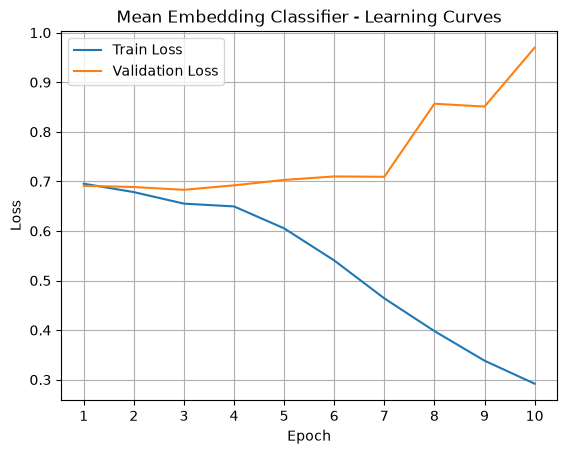

In [23]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.plot(epochs, train_losses, label="Train Loss")
plt.plot(epochs, val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Mean Embedding Classifier - Learning Curves")
plt.legend()
plt.xticks(epochs)
plt.grid(True)
plt.show()

In [24]:
model.load_state_dict(
    torch.load("saved_models/best_single_rnn_model.pth", map_location="cpu")
)

test_loss = 0.0
correct = 0
total = 0

model.eval()

with torch.no_grad():
    for inputs, labels in test_loader:
        outputs = model(inputs)
        loss = criterion(outputs, labels)

        test_loss += loss.item()

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

avg_test_loss = test_loss / len(test_loader)
test_accuracy = correct / total

print(f"Test Loss: {avg_test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Test Loss: 0.7204
Test Accuracy: 0.6420


The model performs even worse, reducing the sequence length to 128 indeed makes the RNN much faster but is too short of a context for it to predict in a decent way.